# Spillover comparison

Read the results of matching experiments at different spillover values. Run notebook 01 first if you want to create new scenarios. This notebook never retrains agents.

In [1]:
import json

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

In [2]:
scenario_directories = {
    0.2: "../results/followup/spillover_02",
    0.0: "../results/followup/spillover_00",
}

manifests = {}
for spillover, directory in scenario_directories.items():
    with open(f"{directory}/manifest.json", encoding="utf-8") as file:
        manifests[spillover] = json.load(file)
    if manifests[spillover]["environment"]["spillover"] != spillover:
        raise ValueError(f"Spillover value does not match {directory}")

reference = next(iter(manifests.values()))
reference_environment = dict(reference["environment"])
reference_environment.pop("spillover")
for spillover, manifest in manifests.items():
    other_environment = dict(manifest["environment"])
    other_environment.pop("spillover")
    if other_environment != reference_environment or manifest["training"] != reference["training"]:
        raise ValueError(f"Settings differ beyond spillover at {spillover}")

print("Scenario settings match except for spillover.")

Scenario settings match except for spillover.


## Policy outcomes

Compare policies within each setting first. Absolute pollution changes when spillover changes, even if the policies do not.

In [3]:
policy_tables = []
run_tables = {}

for spillover, directory in scenario_directories.items():
    policy_table = pd.read_csv(f"{directory}/policy_summary.csv")
    policy_table.insert(0, "spillover", spillover)
    policy_tables.append(policy_table)
    run_tables[spillover] = pd.read_csv(f"{directory}/run_summary.csv")

policy_results = pd.concat(policy_tables, ignore_index=True)
display(policy_results[["spillover", "policy", "runs",
                        "mean_regional_pollution_mean", "mitigation_cost_mean",
                        "threshold_exceedance_mean"]].round(3))

,spillover,policy,runs,mean_regional_pollution_mean,mitigation_cost_mean,threshold_exceedance_mean
0,0.2,fixed_medium,1,23.880,800.000,0.142
1,0.2,iql_global,20,24.974,757.432,0.197
2,0.2,iql_local,20,26.179,527.472,0.252
3,0.2,iql_mixed,20,25.857,573.795,0.223
4,0.2,random,20,23.911,932.278,0.149
5,0.2,threshold,1,25.960,540.200,0.221
6,0.0,fixed_medium,1,17.514,800.000,0.000
7,0.0,iql_global,20,18.967,659.702,0.026
8,0.0,iql_local,20,20.201,430.915,0.051
9,0.0,iql_mixed,20,19.922,461.272,0.037


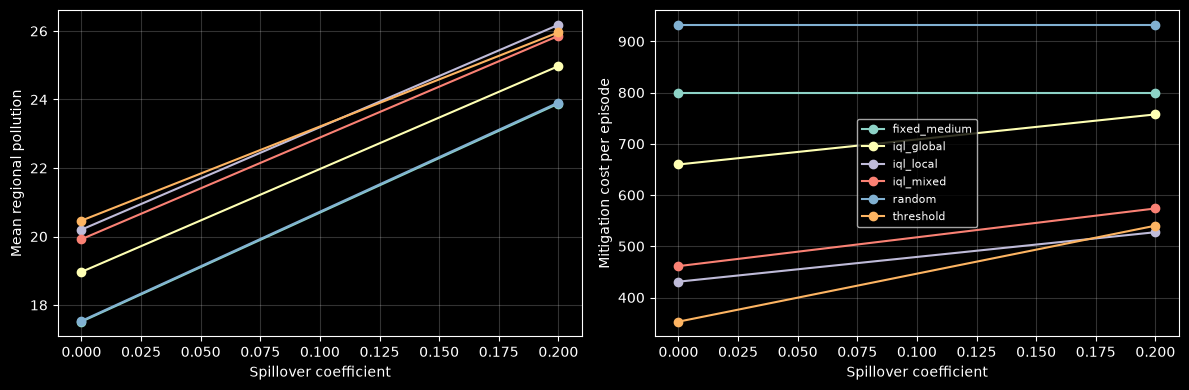

In [4]:
figure, axes = plt.subplots(1, 2, figsize=(12, 4))
metrics = (("mean_regional_pollution_mean", "Mean regional pollution"),
           ("mitigation_cost_mean", "Mitigation cost per episode"))

for axis, (column, label) in zip(axes, metrics):
    for policy, rows in policy_results.groupby("policy"):
        rows = rows.sort_values("spillover")
        axis.plot(rows["spillover"], rows[column], marker="o", label=policy)
    axis.set(xlabel="Spillover coefficient", ylabel=label)
    axis.grid(alpha=0.2)

axes[1].legend(loc="best", fontsize=8)
figure.tight_layout()
plt.show()

In [5]:
paired_rows = []
metrics = ("mean_regional_pollution", "mitigation_cost", "threshold_exceedance")

for spillover, run_table in run_tables.items():
    global_runs = run_table[run_table["policy"] == "iql_global"].set_index("training_seed")
    local_runs = run_table[run_table["policy"] == "iql_local"].set_index("training_seed")
    if set(global_runs.index) != set(local_runs.index) or global_runs.empty:
        raise ValueError(f"Local and global runs need the same training seeds at {spillover}")
    for seed in global_runs.index:
        for metric in metrics:
            paired_rows.append({
                "spillover": spillover, "training_seed": seed, "metric": metric,
                "global_minus_local": global_runs.loc[seed, metric] - local_runs.loc[seed, metric],
            })

paired_results = pd.DataFrame(paired_rows)
gap_summary = (paired_results.groupby(["spillover", "metric"])["global_minus_local"]
               .agg(["mean", "std", "count"]).reset_index())
display(gap_summary.round(3))

,spillover,metric,mean,std,count
0,0.0,mean_regional_pollution,-1.234,0.821,20
1,0.0,mitigation_cost,228.788,118.803,20
2,0.0,threshold_exceedance,-0.025,0.029,20
3,0.2,mean_regional_pollution,-1.205,1.068,20
4,0.2,mitigation_cost,229.960,137.107,20
5,0.2,threshold_exceedance,-0.055,0.068,20


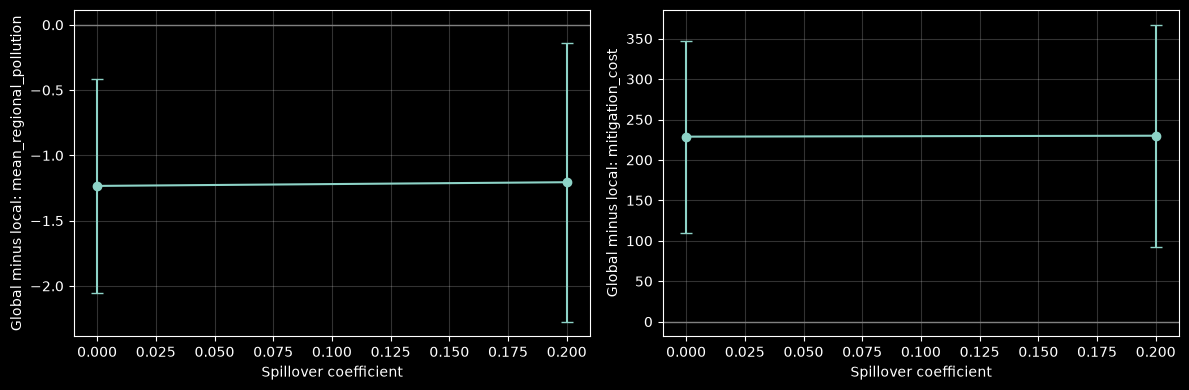

In [6]:
figure, axes = plt.subplots(1, 2, figsize=(12, 4))
for axis, metric in zip(axes, ("mean_regional_pollution", "mitigation_cost")):
    rows = gap_summary[gap_summary["metric"] == metric].sort_values("spillover")
    axis.errorbar(rows["spillover"], rows["mean"], yerr=rows["std"],
                  marker="o", capsize=4)
    axis.axhline(0, color="gray", linewidth=1)
    axis.set(xlabel="Spillover coefficient", ylabel=f"Global minus local: {metric}")
    axis.grid(alpha=0.2)

figure.tight_layout()
plt.show()

In [7]:
if len(scenario_directories) >= 2:
    first_spillover = next(iter(scenario_directories))
    last_spillover = next(reversed(scenario_directories))
    first = paired_results[paired_results["spillover"] == first_spillover]
    last = paired_results[paired_results["spillover"] == last_spillover]
    changes = first.merge(last, on=["training_seed", "metric"], suffixes=("_first", "_last"))
    expected_rows = len(first)
    if len(changes) != expected_rows or len(last) != expected_rows:
        raise ValueError("The two spillover settings need the same paired training seeds.")
    changes["gap_change"] = (changes["global_minus_local_first"]
                             - changes["global_minus_local_last"])
    print(f"Gap at {first_spillover} minus gap at {last_spillover}")
    display(changes.groupby("metric")["gap_change"]
            .agg(["mean", "std", "count"]).round(3))

Gap at 0.2 minus gap at 0.0


,mean,std,count
metric,,,
mean_regional_pollution,0.028,1.609,20
mitigation_cost,1.172,197.729,20
threshold_exceedance,-0.030,0.084,20


## Results Summary

With spillover **0.2**, global-reward Q-learning had **1.21 less pollution** and **230 more cost** than local-reward Q-learning on average. Its pollution was lower in **18 of 20** paired training runs, and its cost was higher in **all 20**. With spillover **0.0**, the corresponding differences were **1.23 less pollution** and **229 more cost**; pollution was lower in **19 of 20** runs and cost higher in **all 20**.

The change in the pollution gap between settings was only **+0.03** (gap at 0.2 minus gap at 0.0), while its standard deviation across paired seeds was **1.61**. The cost-gap change was about **+1.17**, with a standard deviation of **198**. These runs do not show a clear change in the global-versus-local tradeoff when neighbor spillover is removed. This suggests that the shared reward's lower pollution in this simulator is not solely driven by the neighbor term.

Absolute pollution is lower at zero spillover for every policy because neighboring emissions no longer enter a region's load. That level shift should not be confused with a change in which reward design performs better. The error bars show variation across training runs, not a confidence interval or evidence about real-world regions.